# **Project Name**    -  Customer Satisfaction Score Prediction


##### **Project Type**    - Artificial Neural Network (Deep Learning) - Classification
##### **Contribution**    - Individual


# **Project Summary -**

DeepCSAT: E-Commerce Customer Satisfaction Score Prediction is a deep learning project where we seek to predict the CSAT score using an Artificial Neural Network (ANN).

In this project, we will have interaction data between customers and the customer support department where we will have information about the support channel, category of issue, feedback from the customer, information about the product, order and customer service agent.

The main goal of this project is to create a multiclass classification model which will predict one of the five CSAT scores from 1 to 5.Data cleaning, exploratory data analysis, feature engineering, data preprocessing, development of the ANN model and performance evaluation are the stages of this project.

Proper classification metrics will be chosen for performance evaluation, with particular focus on the imbalance of the CSAT scores distribution.Ultimately, the model will be interpreted and prepared for local deployment in order to provide predictions and useful insights.

# **GitHub Link -**

https://github.com/Someshwar24/Customer-Satisfaction-Score-Prediction

# **Problem Statement**


Customer satisfaction plays a vital role in any e-commerce firm since it impacts factors such as customer loyalty and retention as well as business growth. However, performing manual analysis of customer interactions and feedback might take too much time.

In this project, we intend to build an Artificial Neural Network (ANN) that will predict customer satisfaction based on historical interactions of customers. The task can be formulated as multiclass classification since the ANN is supposed to classify customer satisfaction as ratings between 1 and 5.

Classification evaluation metrics will be used to assess the performance of the model; however, it should be taken into account that the class distribution in the available ratings is uneven.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Dense,Dropout,Input

### Dataset Loading

In [2]:
# Load Dataset

original_df = pd.read_csv("eCommerce_Customer_support_data.csv")
df = original_df.copy()
df.head()

/usr/local/lib/python3.13/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,Unique id,channel_name,category,Sub-category,Customer Remarks,Order_id,order_date_time,Issue_reported at,issue_responded,Survey_response_Date,Customer_City,Product_category,Item_price,connected_handling_time,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,7e9ae164-6a8b-4521-a2d4-58f7c9fff13f,Outcall,Product Queries,Life Insurance,NaN,c27c9bb4-fa36-4140-9f1f-21009254ffdb,NaN,01/08/2023 11:13,01/08/2023 11:47,01-Aug-23,NaN,NaN,NaN,NaN,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,b07ec1b0-f376-43b6-86df-ec03da3b2e16,Outcall,Product Queries,Product Specific Information,NaN,d406b0c7-ce17-4654-b9de-f08d421254bd,NaN,01/08/2023 12:52,01/08/2023 12:54,01-Aug-23,NaN,NaN,NaN,NaN,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,200814dd-27c7-4149-ba2b-bd3af3092880,Inbound,Order Related,Installation/demo,NaN,c273368d-b961-44cb-beaf-62d6fd6c00d5,NaN,01/08/2023 20:16,01/08/2023 20:38,01-Aug-23,NaN,NaN,NaN,NaN,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,eb0d3e53-c1ca-42d3-8486-e42c8d622135,Inbound,Returns,Reverse Pickup Enquiry,NaN,5aed0059-55a4-4ec6-bb54-97942092020a,NaN,01/08/2023 20:56,01/08/2023 21:16,01-Aug-23,NaN,NaN,NaN,NaN,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,ba903143-1e54-406c-b969-46c52f92e5df,Inbound,Cancellation,Not Needed,NaN,e8bed5a9-6933-4aff-9dc6-ccefd7dcde59,NaN,01/08/2023 10:30,01/08/2023 10:32,01-Aug-23,NaN,NaN,NaN,NaN,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


### Dataset First View

In [3]:
# Dataset First Look
print("Dataset shape:",df.shape)

Dataset shape: (85907, 20)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 85907 entries, 0 to 85906
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unique id                85907 non-null  object 
 1   channel_name             85907 non-null  object 
 2   category                 85907 non-null  object 
 3   Sub-category             85907 non-null  object 
 4   Customer Remarks         28742 non-null  object 
 5   Order_id                 67675 non-null  object 
 6   order_date_time          17214 non-null  object 
 7   Issue_reported at        85907 non-null  object 
 8   issue_responded          85907 non-null  object 
 9   Survey_response_Date     85907 non-null  object 
 10  Customer_City            17079 non-null  object 
 11  Product_category         17196 non-null  object 
 12  Item_price               17206 non-null  float64
 13  connected_handling_time  242 non-null    float64
 14  Agent_name            

#### Duplicate Values

In [5]:
# Dataset Duplicate Value Count

df.duplicated().sum()

np.int64(0)

#### Missing Values/Null Values

In [6]:
# Missing Values/Null Values Count

df.isna().sum()

,0
Unique id,0
channel_name,0
category,0
Sub-category,0
Customer Remarks,57165
Order_id,18232
order_date_time,68693
Issue_reported at,0
issue_responded,0
Survey_response_Date,0


## ***2. Understanding Your Variables***

In [7]:
# Dataset Columns

print("Dataset columns:", df.columns.tolist())

Dataset columns: ['Unique id', 'channel_name', 'category', 'Sub-category', 'Customer Remarks', 'Order_id', 'order_date_time', 'Issue_reported at', 'issue_responded', 'Survey_response_Date', 'Customer_City', 'Product_category', 'Item_price', 'connected_handling_time', 'Agent_name', 'Supervisor', 'Manager', 'Tenure Bucket', 'Agent Shift', 'CSAT Score']


In [8]:
# Dataset Describe

df.describe()

,Item_price,connected_handling_time,CSAT Score
count,17206.000000,242.000000,85907.000000
mean,5660.774846,462.400826,4.242157
std,12825.728411,246.295037,1.378903
min,0.000000,0.000000,1.000000
25%,392.000000,293.000000,4.000000
50%,979.000000,427.000000,5.000000
75%,2699.750000,592.250000,5.000000
max,164999.000000,1986.000000,5.000000


### Check Unique Values for each variable.

In [9]:
# Check Unique Values for each variable.

for col in df.columns:
  print(f"Unique values in {col} :", df[col].nunique())

Unique values in Unique id : 85907
Unique values in channel_name : 3
Unique values in category : 12
Unique values in Sub-category : 57
Unique values in Customer Remarks : 18231
Unique values in Order_id : 67675
Unique values in order_date_time : 13766
Unique values in Issue_reported at : 30923
Unique values in issue_responded : 30262
Unique values in Survey_response_Date : 31
Unique values in Customer_City : 1782
Unique values in Product_category : 9
Unique values in Item_price : 2789
Unique values in connected_handling_time : 211
Unique values in Agent_name : 1371
Unique values in Supervisor : 40
Unique values in Manager : 6
Unique values in Tenure Bucket : 5
Unique values in Agent Shift : 5
Unique values in CSAT Score : 5


In [10]:
num_cols = df.select_dtypes(include="number")
cat_cols = df.select_dtypes(exclude="number")

print(num_cols)
print(cat_cols)

       Item_price  connected_handling_time  CSAT Score
0             NaN                      NaN           5
1             NaN                      NaN           5
2             NaN                      NaN           5
3             NaN                      NaN           5
4             NaN                      NaN           5
...           ...                      ...         ...
85902         NaN                      NaN           4
85903         NaN                      NaN           5
85904         NaN                      NaN           5
85905         NaN                      NaN           4
85906         NaN                      NaN           5

[85907 rows x 3 columns]
                                  Unique id channel_name         category  \
0      7e9ae164-6a8b-4521-a2d4-58f7c9fff13f      Outcall  Product Queries   
1      b07ec1b0-f376-43b6-86df-ec03da3b2e16      Outcall  Product Queries   
2      200814dd-27c7-4149-ba2b-bd3af3092880      Inbound    Order Related   
3     

## 3. ***Data Wrangling***

### Data Wrangling Code

In [11]:
# Missing-value analysis
missing_analysis = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2),
    "Data_Type": df.dtypes.astype(str)
})

missing_analysis = missing_analysis.sort_values(
    by="Missing_Percentage",
    ascending=False
)

missing_analysis[missing_analysis["Missing_Count"] > 0]

,Missing_Count,Missing_Percentage,Data_Type
connected_handling_time,85665,99.72,float64
Customer_City,68828,80.12,object
Product_category,68711,79.98,object
Item_price,68701,79.97,float64
order_date_time,68693,79.96,object
Customer Remarks,57165,66.54,object
Order_id,18232,21.22,object


In [12]:
df.drop(['Unique id','Order_id',"connected_handling_time","Item_price"],axis=1,inplace=True)

In [13]:
df.dropna(subset=["CSAT Score"], inplace=True)

print("Missing CSAT scores:", df["CSAT Score"].isnull().sum())

Missing CSAT scores: 0


In [14]:
df['Customer Remarks'] = df["Customer Remarks"].fillna("")

print("Missing Customer Remarks:", df['Customer Remarks'].isnull().sum())

Missing Customer Remarks: 0


In [15]:
df["Customer_City"] = df["Customer_City"].fillna("Unknown")

print("Missing values:", df["Customer_City"].isnull().sum())

Missing values: 0


In [16]:
df["Product_category"] = df["Product_category"].fillna("Unknown")

print("Missing values:", df["Product_category"].isnull().sum())

Missing values: 0


In [17]:
# Drop raw date columns for the initial model
date_cols = [
    "order_date_time",
    "Issue_reported at",
    "issue_responded",
    "Survey_response_Date"
]

for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce")

    print(f"\n{col}")
    print("Missing values:", df[col].isnull().sum())

df.drop(columns=date_cols, inplace=True)

print("Dataset shape:", df.shape)
print("Remaining columns:", df.columns.tolist())


order_date_time
Missing values: 68693


/tmp/ipykernel_3254/4200309233.py:10: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df[col] = pd.to_datetime(df[col], errors="coerce")



Issue_reported at
Missing values: 53933

issue_responded
Missing values: 54022

Survey_response_Date
Missing values: 0
Dataset shape: (85907, 12)
Remaining columns: ['channel_name', 'category', 'Sub-category', 'Customer Remarks', 'Customer_City', 'Product_category', 'Agent_name', 'Supervisor', 'Manager', 'Tenure Bucket', 'Agent Shift', 'CSAT Score']


/tmp/ipykernel_3254/4200309233.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df[col] = pd.to_datetime(df[col], errors="coerce")


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

CSAT Score
1    11230
2     1283
3     2558
4    11219
5    59617
Name: count, dtype: int64


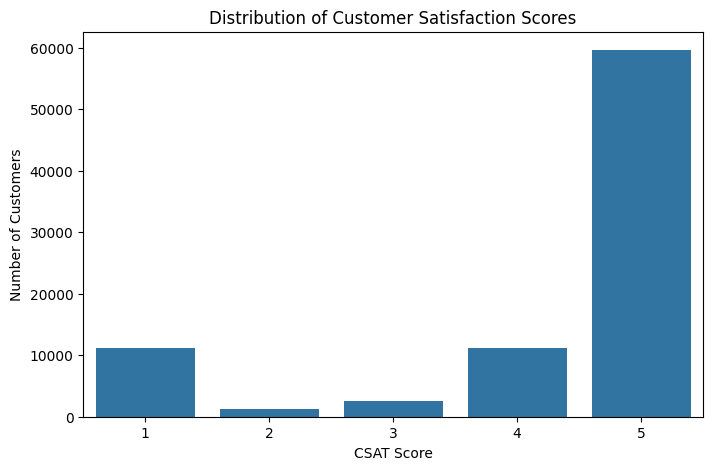

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribution of CSAT scores
print(df["CSAT Score"].value_counts().sort_index())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="CSAT Score")
plt.title("Distribution of Customer Satisfaction Scores")
plt.xlabel("CSAT Score")
plt.ylabel("Number of Customers")
plt.show()

##### 1. Why did you pick the specific chart?

A count plot is suitable for visualizing the distribution of CSAT scores from 1 to 5. It helps us understand how frequently each satisfaction score occurs and identify whether the target variable is balanced or dominated by a particular score.

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify the most and least frequent CSAT scores and reveals any class imbalance. In our dataset, score 5 is the most frequent category, indicating that positive satisfaction ratings dominate the responses. This imbalance should be considered when training and evaluating the ANN model.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Understanding the distribution of customer satisfaction helps businesses identify the prevalence of positive and negative feedback. Detecting low-satisfaction interactions can help support teams investigate service issues and improve customer experience. Since the dataset is imbalanced, metrics such as macro F1-score and balanced accuracy will help us evaluate whether the model can identify less frequent satisfaction categories.

#### Chart - 2

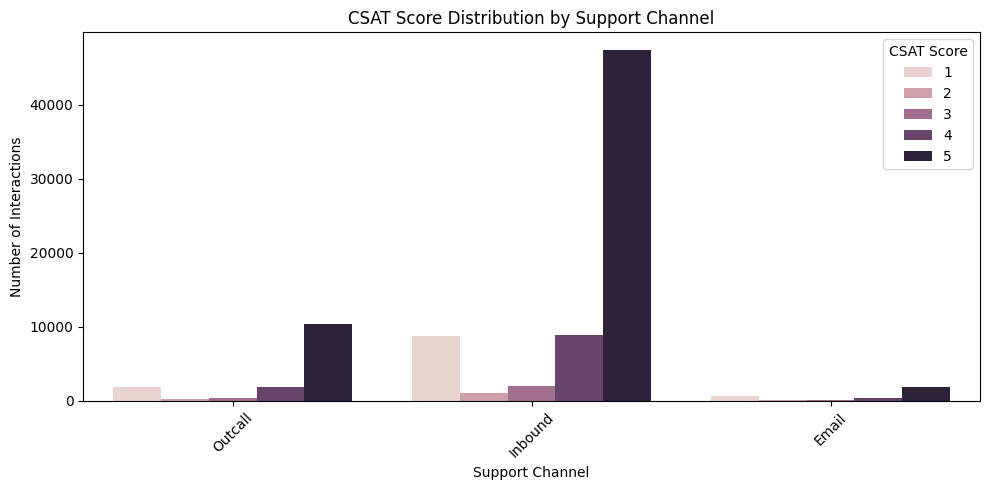

In [19]:
#Chart 2 — CSAT Score Distribution by Support Channel

plt.figure(figsize=(10, 5))

sns.countplot(data=df,x="channel_name", hue="CSAT Score")
plt.title("CSAT Score Distribution by Support Channel")
plt.xlabel("Support Channel")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=45)
plt.legend(title="CSAT Score")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A count plot is suitable for comparing the frequency of different CSAT scores across support channels. It helps us understand how customer satisfaction ratings are distributed among the available channels.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the number of interactions associated with each CSAT score for every support channel. It helps identify which scores are most frequent within each channel and whether the distribution varies across channels. Specific conclusions should be based on the actual plotted results.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Understanding satisfaction patterns across support channels can help businesses identify channels that may need service improvements. This can support better allocation of support resources and help improve the customer experience. However, differences in interaction volume should be considered before comparing channels directly.

#### Chart - 3

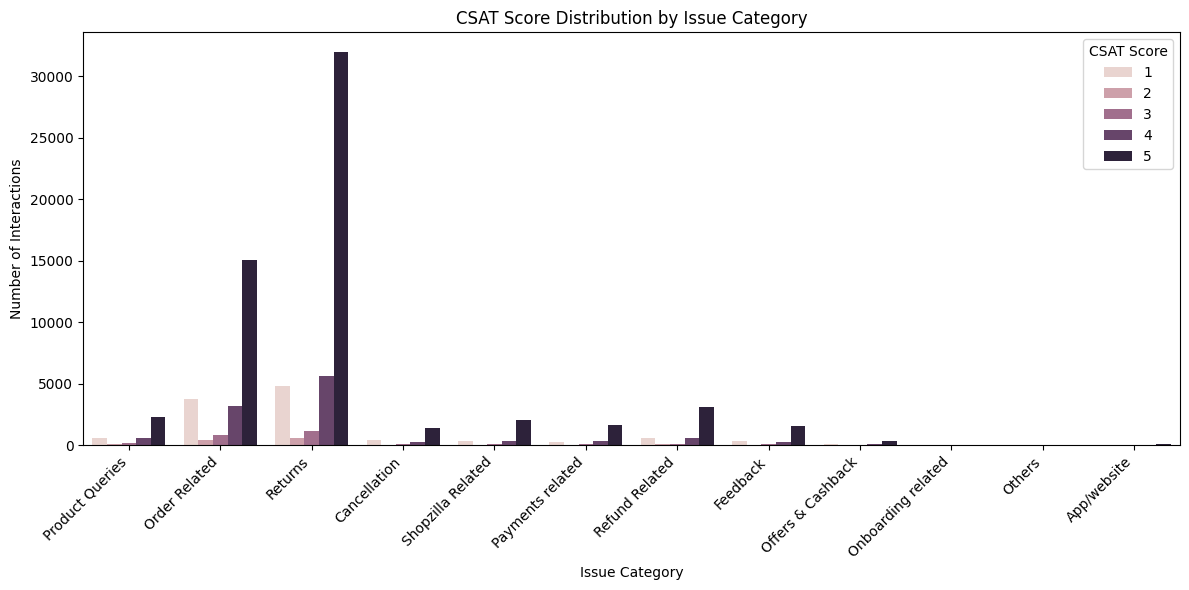

In [20]:
# Chart 3 — CSAT Score Distribution by Issue Category

plt.figure(figsize=(12, 6))

sns.countplot(data=df,x="category",hue="CSAT Score")
plt.title("CSAT Score Distribution by Issue Category")
plt.xlabel("Issue Category")
plt.ylabel("Number of Interactions")
plt.xticks(rotation=45, ha="right")
plt.legend(title="CSAT Score")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A count plot is suitable for comparing the frequency of CSAT scores across different issue categories. It helps us examine how customer satisfaction ratings are distributed among the types of issues reported to customer support.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the number of interactions associated with each satisfaction score within each issue category. It helps identify the most common ratings and whether the score distribution differs across issue types. Specific findings should be based on the actual chart.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Identifying issue categories associated with more low satisfaction ratings can help businesses prioritize service improvements, investigate recurring customer problems, and improve support processes. The counts should be interpreted in the context of each category's total number of interactions.

#### Chart - 4

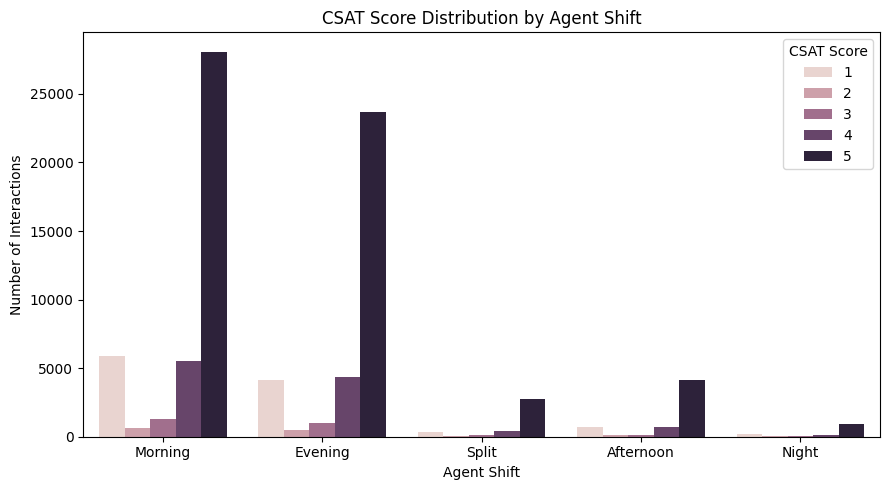

In [21]:
# Chart 4 — CSAT Score Distribution by Agent Shift

plt.figure(figsize=(9, 5))

sns.countplot(data=df,x="Agent Shift",hue="CSAT Score")
plt.title("CSAT Score Distribution by Agent Shift")
plt.xlabel("Agent Shift")
plt.ylabel("Number of Interactions")
plt.legend(title="CSAT Score")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A count plot is suitable for comparing the frequency of different CSAT scores across agent shifts. It helps us examine how customer satisfaction ratings are distributed among the shifts handling customer interactions.

##### 2. What is/are the insight(s) found from the chart?

The chart shows the number of interactions associated with each CSAT score across agent shifts. It helps identify the most frequent ratings within each shift and whether the distributions differ. Specific conclusions should be based on the actual plotted results.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Understanding satisfaction patterns across shifts can help businesses investigate potential differences in support quality, staffing, and workload. These insights may guide staffing and training improvements, although differences in interaction volume and issue complexity should be considered before attributing outcomes to a particular shift.

## ***6. Model Implementation***

In [22]:
# Check missing values in the selected dataset
print("Missing values in each column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDataset shape:", df.shape)

Missing values in each column:
Series([], dtype: int64)

Dataset shape: (85907, 12)


In [23]:
df.head()

,channel_name,category,Sub-category,Customer Remarks,Customer_City,Product_category,Agent_name,Supervisor,Manager,Tenure Bucket,Agent Shift,CSAT Score
0,Outcall,Product Queries,Life Insurance,,Unknown,Unknown,Richard Buchanan,Mason Gupta,Jennifer Nguyen,On Job Training,Morning,5
1,Outcall,Product Queries,Product Specific Information,,Unknown,Unknown,Vicki Collins,Dylan Kim,Michael Lee,>90,Morning,5
2,Inbound,Order Related,Installation/demo,,Unknown,Unknown,Duane Norman,Jackson Park,William Kim,On Job Training,Evening,5
3,Inbound,Returns,Reverse Pickup Enquiry,,Unknown,Unknown,Patrick Flores,Olivia Wang,John Smith,>90,Evening,5
4,Inbound,Cancellation,Not Needed,,Unknown,Unknown,Christopher Sanchez,Austin Johnson,Michael Lee,0-30,Morning,5


In [24]:
df.columns

Index(['channel_name', 'category', 'Sub-category', 'Customer Remarks',
       'Customer_City', 'Product_category', 'Agent_name', 'Supervisor',
       'Manager', 'Tenure Bucket', 'Agent Shift', 'CSAT Score'],
      dtype='object')

In [25]:
import tensorflow as tf
from keras.layers import Dense,Input,Dropout
from keras.models import Sequential
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline,Pipeline
from sklearn.compose import ColumnTransformer
from tensorflow.keras.callbacks import EarlyStopping


X = df.iloc[:,:-1]
y = df.iloc[:,-1]

X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.2)

cat_cols = df.select_dtypes(exclude='number').columns.drop('Customer Remarks')

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ],
    remainder='drop'
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Training count", X_train_encoded.shape)
print("Testing count", X_test_encoded.shape)

y_train =  y_train - 1
y_test = y_test - 1

Training count (68725, 3167)
Testing count (17182, 3167)


In [26]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(X_train_encoded.shape[1],)),
    Dense(128,activation="relu"),
    Dropout(0.5),
    Dense(64,activation="relu"),
    Dense(5,activation="softmax")
])

model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])


early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(X_train_encoded,y_train,epochs=20,batch_size=32,validation_split=0.2,callbacks=[early_stop])

y_pred_prob = model.predict(X_test_encoded)

y_pred = np.argmax(y_pred_prob, axis=1)

y_pred_csat = y_pred + 1

print("Final conversion to CSAT scores: ", y_pred_csat[1:3])

Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.6927 - loss: 0.9487 - val_accuracy: 0.6955 - val_loss: 0.9285
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 20s 11ms/step - accuracy: 0.6960 - loss: 0.9176 - val_accuracy: 0.6964 - val_loss: 0.9276
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.6990 - loss: 0.9018 - val_accuracy: 0.6952 - val_loss: 0.9360
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.7010 - loss: 0.8898 - val_accuracy: 0.6948 - val_loss: 0.9365
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - accuracy: 0.7034 - loss: 0.8752 - val_accuracy: 0.6925 - val_loss: 0.9461
537/537 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Final conversion to CSAT scores:  [5 5]


In [27]:
test_loss, test_accuracy = model.evaluate(X_test_encoded, y_test)

print("Test Loss:", round(test_loss,2))
print("Test Accuracy:", round(test_accuracy,2))

537/537 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6961 - loss: 0.9179
Test Loss: 0.92
Test Accuracy: 0.7


# **Conclusion**

In this project, an artificial neural network was built to predict customer satisfaction scores between 1 and 5 on the basis of e-commerce customer support interactions data. The ANN model included two hidden layers, the first one consisted of 128 and the second of 64 neurons, the use of ReLU activation functions, the dropout layer with the rate of 0.5, and the Softmax output layer for multiclass prediction.

The model was trained via the Adam optimization algorithm and sparse categorical cross-entropy loss function. Early stopping was employed as an additional measure to avoid unnecessary training and potential overfitting.
The final model scored around 70% test accuracy and 0.92 test loss.

Overall, this project gave practical experience in the areas of data preprocessing, encoding of categorical features, building ANN models, applying dropout regularization, early stopping, and model evaluation. Future enhancements may come from better feature engineering, analyzing the text of customer comments, and experimenting with neural network architectures.

In summary, the project illustrates an end-to-end solution for the task of predicting customer satisfaction, emphasizing the need to evaluate classifiers using multiple metrics.